# Cleaning, missing values, integration, and aggregation

Phase I of *Prishtina Taxi Mobility*: which points stay, what changes, what they are joined with, and how they are summarised.

This notebook only reads what the pipeline wrote (`python -m taxi.pipeline run`, see the README). Every number below comes from those outputs, so the notebook and the tables in `reports/` cannot disagree.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from taxi import config, io

# Outputs of a --dev run instead of the full run (for testing the notebook only).
DEV = os.environ.get("TAXI_NOTEBOOK_DEV") == "1"
config.set_dev(DEV)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)


def figure(name):
    display(Image(filename=str(config.figures_dir() / f"{name}.png"), width=900))


def table(name):
    path = io.report_table_path(name)
    if not path.exists():
        print(
            f"{path.relative_to(ROOT)} does not exist yet: run the stage that writes it."
        )
        return None
    return pd.read_csv(path)


print("Reading the outputs of the", "dev run" if DEV else "full run")

Reading the outputs of the full run


## 1. Cleaning

The `clean` stage applies the validity rules to every vehicle, in a fixed order. Phase I removes only values that are **impossible**; values that are unusual but possible (GPS jumps, very high speeds, long trips) stay in the data for outlier detection in Phase II.

| Rule | Check | Action |
|---|---|---|
| R01 | timestamp missing | drop |
| R02 | timestamp outside the study window | drop |
| R03 | latitude or longitude missing | drop |
| R04 | coordinates out of range, or both 0 | drop |
| R08 | exact duplicate of another row (all raw fields) | drop, keep the first |
| R09 | same vehicle and time, different values | keep all, flag |
| R06 | speed below 0 or above `SPEED_MAX_KMH` | set to NA, then impute (M2) |
| R07 | heading outside 0 to 360 | set to NA |
| R05 | outside the Kosovo boundary | keep, flag `in_kosovo = false` |

Every rule writes one line per vehicle to `cleaning_log.csv`, also when it affects nothing. A drop rule that would remove more than `MAX_DROP_SHARE` of a vehicle's rows stops the stage, so a large removal is looked at before it happens.

Two details matter for the duplicates. In `1.csv` and `100.csv`, days 1 to 12 of each month lost their seconds when the files were re-saved in a spreadsheet: there a parked taxi reporting every 10 seconds produces rows that look identical within a minute, although they are separate readings. R08 therefore applies only to rows with seconds. And four vehicles resend records more often than the rest; their exact duplicates were reviewed (the same record sent twice) and R08 may drop them above the limit.

In [2]:
log = io.read_log()
clean_log = log[log["stage"] == "clean"]
rules = clean_log.groupby(["rule_id", "action"], sort=False).agg(
    rows_in=("rows_in", "sum"),
    rows_affected=("rows_affected", "sum"),
    vehicles_affected=("rows_affected", lambda s: int((s > 0).sum())),
)
rules["share"] = (rules["rows_affected"] / rules["rows_in"]).round(5)
print(
    f"MAX_DROP_SHARE = {config.MAX_DROP_SHARE:.0%}, reviewed R08 vehicles: {config.R08_REVIEWED_VEHICLES}"
)
rules

MAX_DROP_SHARE = 1%, reviewed R08 vehicles: [3, 5, 17, 30]


,,rows_in,rows_affected,vehicles_affected,share
rule_id,action,,,,
R01,drop,28590588,0,0,0.00000
R02,drop,28590588,0,0,0.00000
R03,drop,28590588,0,0,0.00000
R04,drop,28590588,0,0,0.00000
R08,drop,28590588,73676,83,0.00258
R09,flag,28516912,425690,81,0.01493
M4,flag,28516912,5969,69,0.00021
R06,set_na,28516912,0,0,0.00000
R07,set_na,28516912,0,0,0.00000


**Every row is accounted for.** Per vehicle, the raw rows in the inventory must equal the rows kept in `points_clean` plus the rows the log records as dropped. `python -m taxi.pipeline check` enforces this; the same sum is shown here.

In [3]:
import pyarrow.parquet as pq

inventory = pd.read_csv(config.RAW_INVENTORY_CSV)
raw = inventory[inventory["bytes"] > 0].set_index("vehicle_id")["rows"]
ids = io.vehicle_ids("clean")
kept = pd.Series(
    {v: pq.ParquetFile(io.points_path("clean", v)).metadata.num_rows for v in ids}
)
dropped = (
    log[log["stage"].isin(["ingest", "clean"]) & (log["action"] == "drop")]
    .groupby("vehicle_id")["rows_affected"]
    .sum()
)
recon = pd.DataFrame(
    {
        "raw": raw.reindex(ids),
        "kept": kept,
        "dropped": dropped.reindex(ids, fill_value=0),
    }
)
recon["difference"] = recon["raw"] - recon["kept"] - recon["dropped"]
print(
    f"{len(recon)} vehicles: {recon['raw'].sum():,} raw rows = {recon['kept'].sum():,} kept "
    f"+ {recon['dropped'].sum():,} dropped; vehicles that do not add up: {(recon['difference'] != 0).sum()}"
)
reviewed = clean_log[clean_log["note"].str.contains("reviewed", na=False)]
reviewed[["vehicle_id", "rule_id", "rows_in", "rows_affected", "note"]]

83 vehicles: 28,590,588 raw rows = 28,516,912 kept + 73,676 dropped; vehicles that do not add up: 0


,vehicle_id,rule_id,rows_in,rows_affected,note
275,3,R08,213223,2358,"exact duplicate of a lower source_row, rows with seconds only; 0 identical-looking min..."
297,5,R08,389568,4540,"exact duplicate of a lower source_row, rows with seconds only; 0 identical-looking min..."
385,17,R08,475662,4857,"exact duplicate of a lower source_row, rows with seconds only; 0 identical-looking min..."
517,30,R08,251728,3769,"exact duplicate of a lower source_row, rows with seconds only; 0 identical-looking min..."


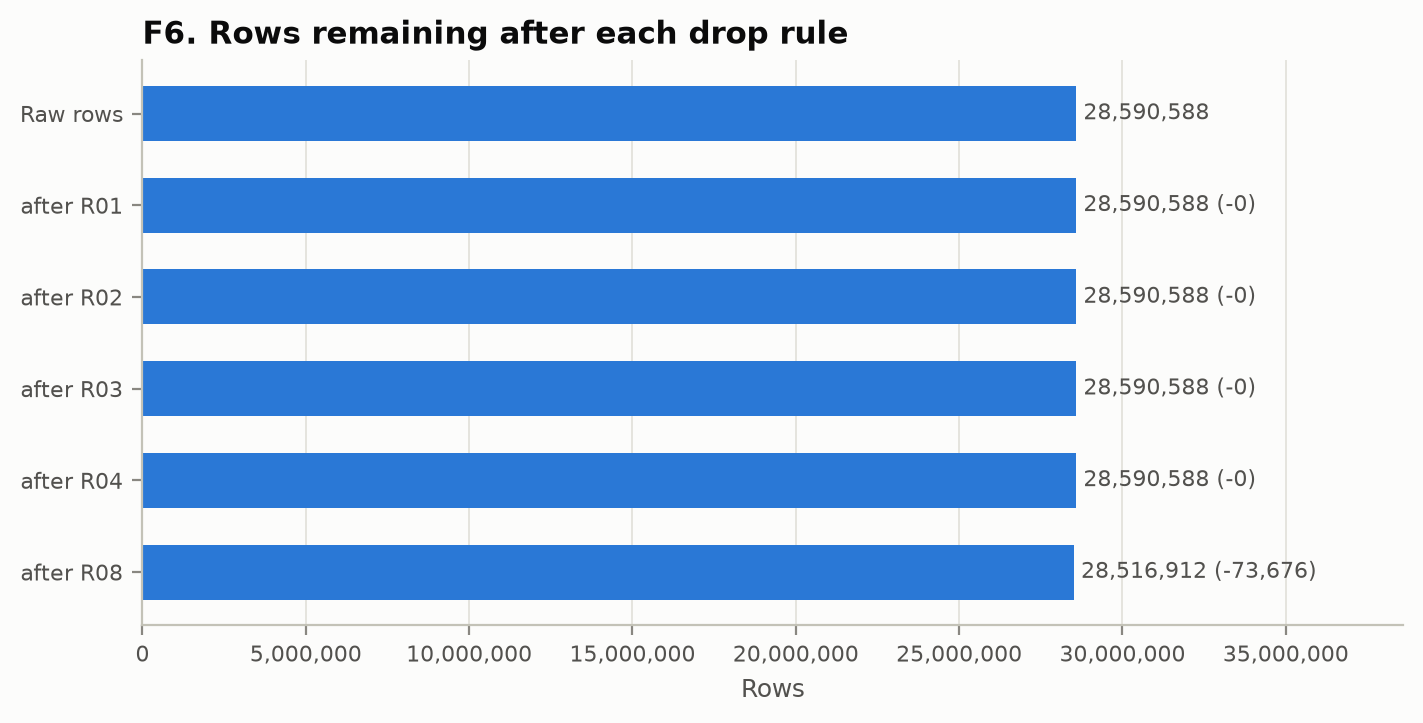

In [4]:
figure("f06_cleaning_funnel")

The map shows the points per cell of 0.01 degrees after the drop rules, with the Kosovo boundary. Points outside Kosovo are real trips abroad and are kept. The map shows cells, never single points, so no vehicle's overnight position can be read from it.

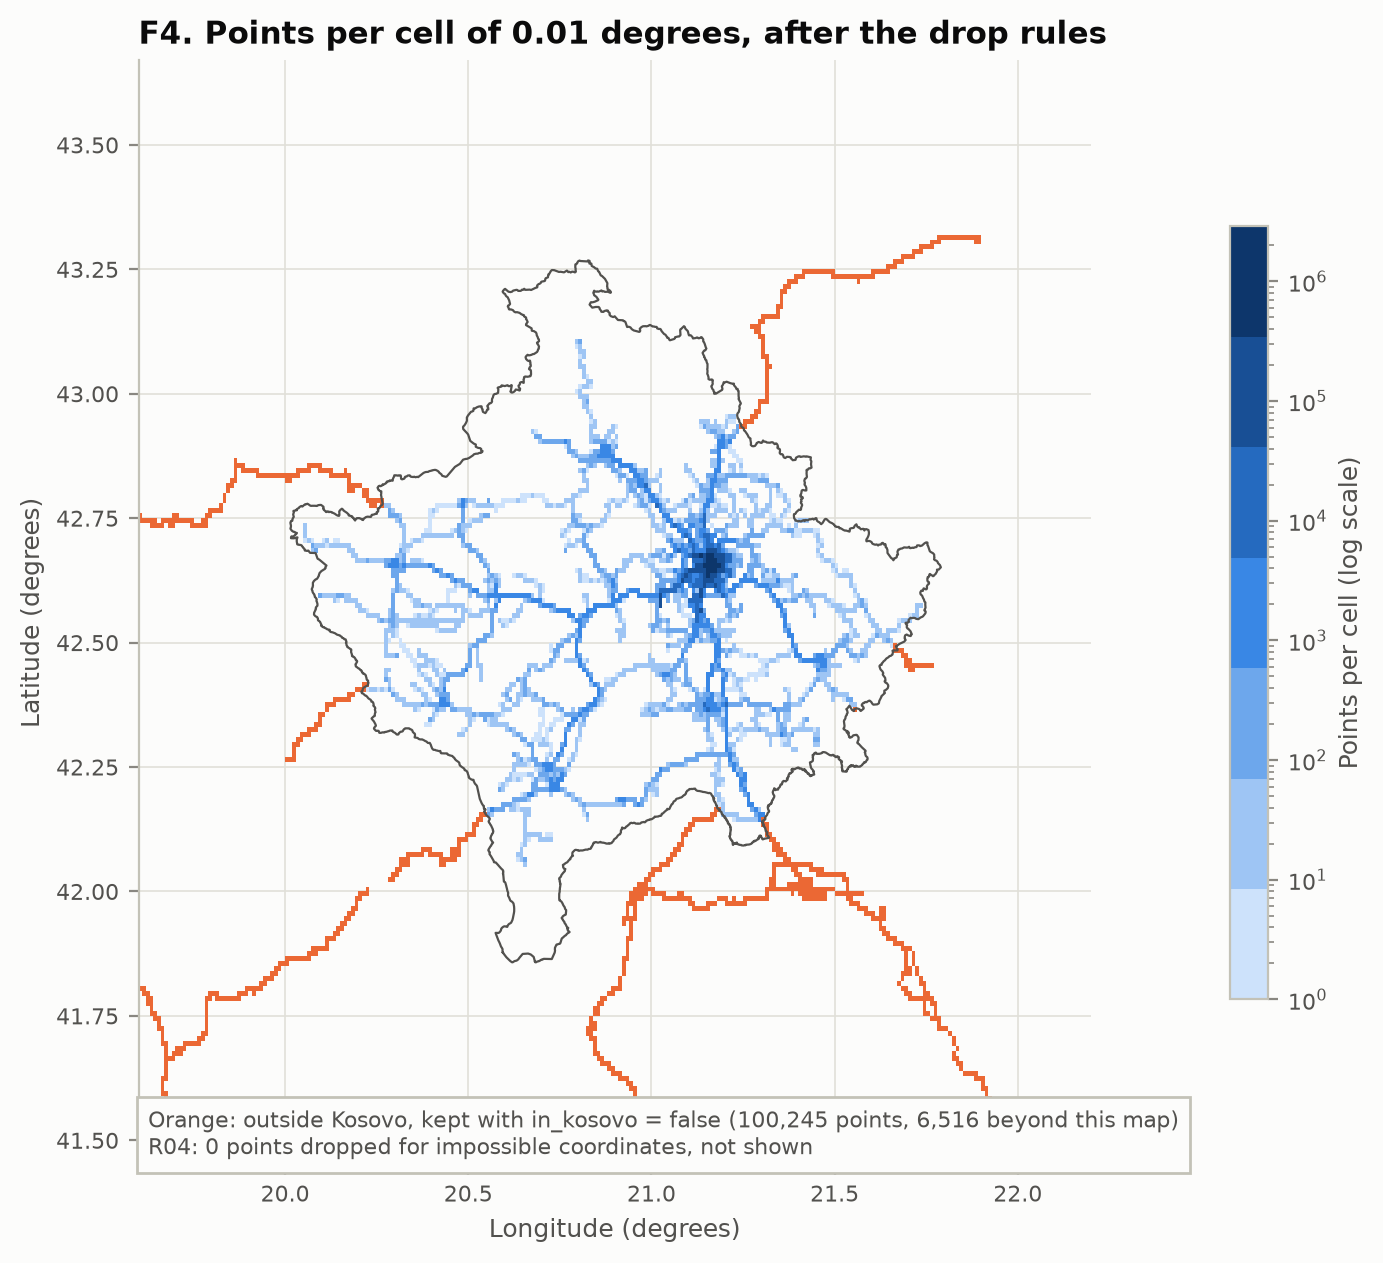

In [5]:
figure("f04_raw_points_map")

**Speed unit.** The dataset author says `Speed` is in km/h. As a check, the reported speed is compared with the speed implied by distance over time on steps of 5 to 60 seconds and at least 10 m (shorter steps are dominated by GPS jitter), with seconds at both ends. If the unit were m/s, the cloud would lie on the line implied = 3.6 x reported.

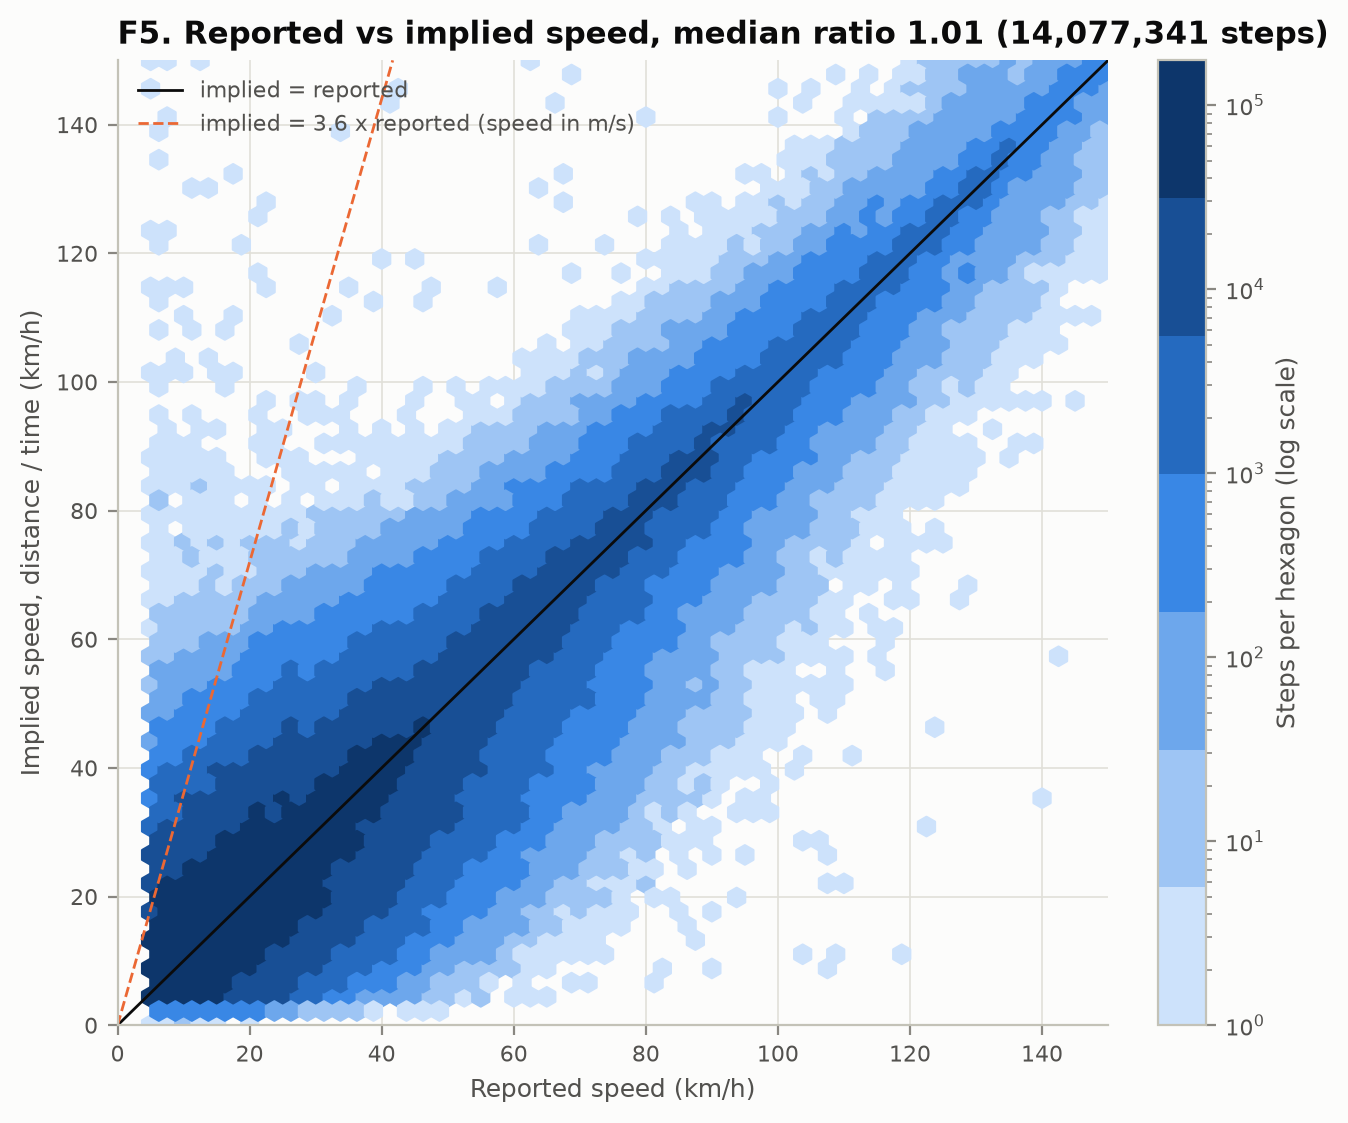

In [6]:
figure("f05_reported_vs_implied_speed")

## 2. Missing values

Missing data comes in four kinds here: missing values in a column, whole files without data, vehicle-days without any point, and gaps, where the time to the next point is longer than `GAP_S`. A gap means "we do not know", not "the taxi was parked": no point is ever created to fill it, and the step across it is left out of every duration and distance.

| Rule | Missing | Strategy |
|---|---|---|
| M1 | time or coordinates | drop (R01, R03): a position cannot be guessed reliably |
| M2 | speed | fill from neighbouring steps of at most `IMPUTE_MAX_DT_S`, flagged `speed_imputed`; otherwise NA |
| M3 | `di1`, `di2`, `di3` | leave NA, never impute |
| M4 | time between points (gaps) | flag `gap_after`; no synthetic points |
| M5 | empty files | excluded, listed in the inventory |
| M6 | vehicle-days without data | no row in `vehicle_day`; coverage is reported |

In [7]:
table("missing_strategy")

,kind,column,n,count,share,mechanism,rule,strategy,why
0,value,ts_utc,28590588,0,0.000000,none in the data,M1,drop (R01),a time cannot be guessed reliably
1,value,lon,28590588,0,0.000000,none in the data,M1,drop (R03),a position cannot be guessed reliably
2,value,lat,28590588,0,0.000000,none in the data,M1,drop (R03),a position cannot be guessed reliably
3,value,speed_kmh,28590588,0,0.000000,none in the data,M2,"fill with IMPUTE_METHOD when both steps are short, else leave NA",between two short steps the speed changes little
4,value,heading_deg,28590588,0,0.000000,none in the data,-,leave NA,not needed for durations or distances
5,value,di1,28590588,0,0.000000,none in the data,M3,leave NA,an on/off state cannot be inferred from neighbours
6,value,di2,28590588,4,0.000000,parse failure or empty field,M3,leave NA,an on/off state cannot be inferred from neighbours
7,value,di3,28590588,4,0.000000,parse failure or empty field,M3,leave NA,an on/off state cannot be inferred from neighbours
8,file,all,85,2,0.023529,"raw files of vehicles [8, 27] are empty (0 bytes); the source gives no reason",M5,"exclude, list in the inventory and the report",there is nothing to repair
9,gap,dt_s,28516829,5969,0.000209,"gaps per 10,000 steps: 55.81 after the ignition is off, 0.04 after it is on, so not MC...",M4,"set gap_after, leave the step out of durations and distances",positions between two distant points are unknown; no points are created


**Why the gaps are not missing at random.** If gaps were missing completely at random (MCAR), they would start equally often whatever the vehicle was doing. The rate of gaps per 10,000 steps, split by the ignition state at the point before the gap, shows whether that holds. Whether they are missing at random or not at random (MAR or MNAR) cannot be told from observed data; how the devices report (little or nothing while switched off) argues for the second.

In [8]:
gaps = table("missing_gaps")
gaps[gaps["group"] == "di1 before the gap"]

,group,value,steps,gaps,gaps_per_10000_steps
0,di1 before the gap,False,1049302,5856,55.809
1,di1 before the gap,True,27467527,113,0.041


**Choosing the imputation by test, not by guess.** Among the points M2 could fill whose speed is known, 5% are hidden at random (seed 42), filled by each method, and compared with the hidden truth. The method with the lowest mean absolute error is `IMPUTE_METHOD`.

In [9]:
print("IMPUTE_METHOD =", config.IMPUTE_METHOD)
table("imputation_eval")

IMPUTE_METHOD = implied_speed


,method,n_hidden,n_with_estimate,n_compared,mae_kmh,median_ae_kmh,p90_ae_kmh,chosen
0,implied_speed,1371646,1353414,1221897,4.891,2.858,12.579,True
1,interpolate,1371646,1238396,1221897,5.187,3.286,13.500,False
2,previous,1371646,1303283,1221897,6.938,4.000,19.000,False


## 3. Integration

The points are joined with four other sources inside the `clean` stage: the Kosovo boundary (Who's On First country polygon), the municipalities (Who's On First `localadmin` layer), a 500 m grid in metres (EPSG:32634), and the official 2023 holiday calendar. One WOF polygon carries the wrong name ("Fushe Kosova" for a piece of North Mitrovica), so municipalities are labelled by WOF id, which gives the 38 municipalities of Kosovo. The local date and hour come from `ts_local` in pandas, never from DuckDB, whose date functions use the session time zone.

The table gives, per source, the join key, the time base, and the rows matched and unmatched with the reason.

In [10]:
table("integration_summary")

,source,join_key,time_base,unit,n,matched,unmatched,why_unmatched
0,"vehicle files (Kaggle, 85 CSV)",file name -> vehicle_id,"DeviceDateTime on the device clock (DEVICE_TZ), stored as ts_utc",files,85,83,2,"empty files (0 bytes), excluded by M5; every vehicle_id is unique and every file with ..."
1,"Kosovo boundary (WOF country polygon, HDX)","lon, lat inside the polygon",none,points,28516912,28416667,100245,"points outside Kosovo, kept with in_kosovo = false (R05)"
2,"municipalities (WOF localadmin polygons, HDX)","lon, lat inside the polygon",none,points,28516912,28416540,100372,"100,245 outside Kosovo; 127 inside the country polygon but in no municipality polygon"
3,"grid (500 m cells, EPSG:32634)","lon, lat projected to metres",none,points,28516912,28516912,0,every point with coordinates gets a cell
4,calendar_2023.csv (Ministry of Internal Affairs),date_local,local date from ts_local (Europe/Skopje),points,28516912,28516912,0,"the stage stops if a date is missing; 5,937,268 points on weekends, 171,533 on the hol..."


Where the points fall, by municipality (a fleet-wide count with DuckDB over the per-vehicle Parquet files):

In [11]:
import duckdb

files = (config.points_dir("clean") / "*.parquet").as_posix()
by_area = duckdb.sql(
    f"""
    SELECT coalesce(municipality, CASE WHEN in_kosovo THEN '(inside Kosovo, no polygon)'
                                       ELSE '(outside Kosovo)' END) AS municipality,
           count(*) AS points
    FROM read_parquet('{files}')
    GROUP BY 1
    ORDER BY points DESC
    """
).df()
by_area["share"] = (by_area["points"] / by_area["points"].sum()).round(4)
by_area.head(12)

,municipality,points,share
0,Prishtine,26206543,0.9190
1,Fushe Kosovo,620836,0.0218
2,GraCanica,558170,0.0196
3,Lipjan,326545,0.0115
4,Obiliq,141697,0.0050
5,(outside Kosovo),100245,0.0035
6,Ferizaj,79339,0.0028
7,Vushtrri,67560,0.0024
8,Gllogovc,54253,0.0019
9,Prizren,46491,0.0016


## 4. Aggregation

Three tables summarise the clean points at coarser levels: `vehicle_day` (one row per vehicle and local date with data), `cell_hour` (one row per grid cell, date, and hour with a point), and `fleet_hour` (one row per local hour of the study window, with zeros where no vehicle was active).

A parked taxi reports about every 6 minutes and a moving one every 10 seconds, so counting points would over-weight moving time. Every duration, distance, and share is therefore a sum over **steps** (from a point to the next point of the same vehicle), leaving out steps across a gap, and every average speed is distance over time. Average speeds use only steps with seconds at both ends: where the seconds were lost, the step time, and so the speed, is wrong. The stage stops if the aggregates do not reconcile with the points.

In [12]:
vehicle_day = io.read_table("vehicle_day")
cell_hour = io.read_table("cell_hour")
fleet_hour = io.read_table("fleet_hour")
print(
    f"vehicle_day: {len(vehicle_day):,} rows, {vehicle_day['vehicle_id'].nunique()} vehicles, "
    f"{vehicle_day['km'].sum():,.0f} km, {vehicle_day['observed_h'].sum():,.0f} observed hours"
)
print(f"cell_hour: {len(cell_hour):,} rows, {cell_hour['cell_id'].nunique():,} cells")
print(f"fleet_hour: {len(fleet_hour):,} rows (92 days x 24 hours)")
vehicle_day.drop(columns="vehicle_id").describe().T[["mean", "50%", "max"]].round(2)

vehicle_day: 6,519 rows, 83 vehicles, 1,235,768 km, 149,559 observed hours


cell_hour: 611,316 rows, 8,487 cells
fleet_hour: 2,208 rows (92 days x 24 hours)


,mean,50%,max
n_points,4374.43,4571.00,11065.00
observed_h,22.94,24.00,24.18
moving_h,6.47,6.76,15.86
km,189.56,185.79,800.03
avg_speed_moving_kmh,27.24,26.29,95.34
max_speed_kmh,96.68,103.00,186.00
di1_share,0.46,0.46,1.00
di2_share,0.17,0.17,0.65
di3_share,0.36,0.21,1.00
n_gaps,0.92,0.00,26.00


**What aggregation gains and loses.** The coefficient of variation of speed at each level shows the trade-off Tan et al. describe (section 2.3.1): over enough data, aggregates are more stable than single points, but small groups (a cell-hour with one or two steps) are not.

In [13]:
table("aggregation_summary")

,level,rows,n_with_speed,mean_speed_kmh,std_speed_kmh,cv
0,point (moving points),17664144,17664144,27.1150,20.4021,0.7524
1,cell_hour,611316,607230,56.1324,44.2956,0.7891
2,vehicle_day,6519,5971,27.2363,8.1559,0.2995


The hourly profile of the fleet, with the edges of the time-of-day buckets used as features (`TOD_BUCKETS`). The buckets should follow the changes in activity, which this figure checks.

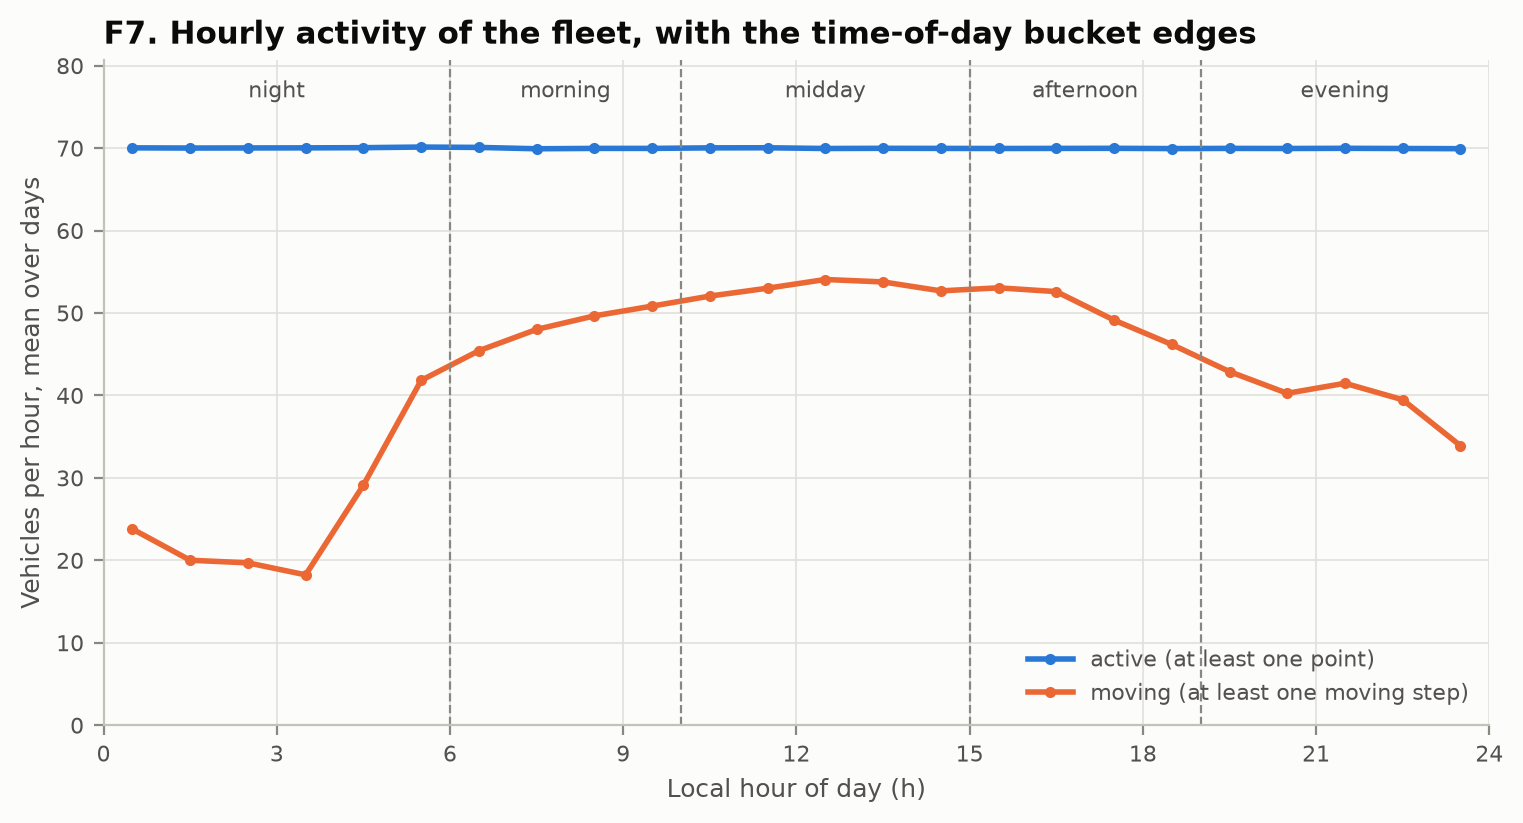

In [14]:
figure("f07_hourly_activity")